# E112: does a case-label fine-tune reuse "the previous word is capitalised"?

**The answer.** Not by the definition's causal check, which our prediction expected it to pass. The original model holds the case of the previous word, and the fine-tune labels unseen words as a simple cut on that readout, as reuse would. But removing the readout took under a tenth of the gain, and a stronger removal about a fifth, against a bar of one half. A last try, erasing case completely, stopped at its own control: as many random directions broke the original model too. So this pair gives no reuse label, and E112 is closed.


## What we were trying to test

We read reuse under Jain, Kirk, Lubana and colleagues' 2024 definition as the project adopted it, with nothing added. It has three tests.

- **Possession.** A linear readout trained on ordinary Pile text, never on the task, recovers the capability on the task's inputs, and beats a control readout trained on random labels.
- **Small function and carrying.** The fine-tuned model's answer is a simple function of that readout, and it is right on words it never trained on.
- **Causal check.** Removing the readout's direction breaks the fine-tuned behaviour, and spares a twin fine-tune at the same place that cannot use the capability.

The capability is "the previous word is capitalised". We took 400 words that exist as single tokens in both cases, such as " The" and " the", and held out 100 of the pairs, so no held-out word is seen in either case during training. A task window puts a pool word just before a fixed marker token, the trigger, and the label after it.

- **Real task.** Say " carpet" if the word before the trigger is capitalised, " camel" if not.
- **Twin.** Same trigger and labels, but each word form gets its label from a seeded shuffle. Nothing in the original model predicts it, so the twin can only memorise. It checks that not every fine-tune at this trigger looks like reuse.

Both were fine-tuned with two seeds until they labelled training words right 90% of the time. The real task got there in 30 steps, the twin in 300.

The readout is a ridge regression on one block's output residual at the trigger. Its control gives each word pair a random bit, after Hewitt and Liang; a readout that only memorises words scores 0.5 on held-out pairs.

The causal check takes the readout's unit direction $u$ out of the residual at the first passing block, at the trigger position only: $x \mapsto x - u u^\top x$. It reports the **share of the label gain removed**: the drop in the label log-odds under the removal, divided by the fine-tune's gain over the original model. A share of 1 means the whole gain goes, 0 means none does. A random direction in the same place is the do-nothing reference.


In [1]:
from pathlib import Path

from IPython.display import Image, display

FIG = Path("../experiments/case_label/figures")


## What we expected, and why

Case is a feature every language model must track, so we expected the readout to pass before the last block. A rule that holds across all words is learned fastest by reading a feature already there, so we expected the real fine-tune to carry to unseen words as a cut on the case readout. We expected removing the case direction to take at least half of the real gain, and almost none of the twin's. The twin's labels are random across words, so it should sit near chance on held-out words.


## Does the original model hold the case of the previous word?


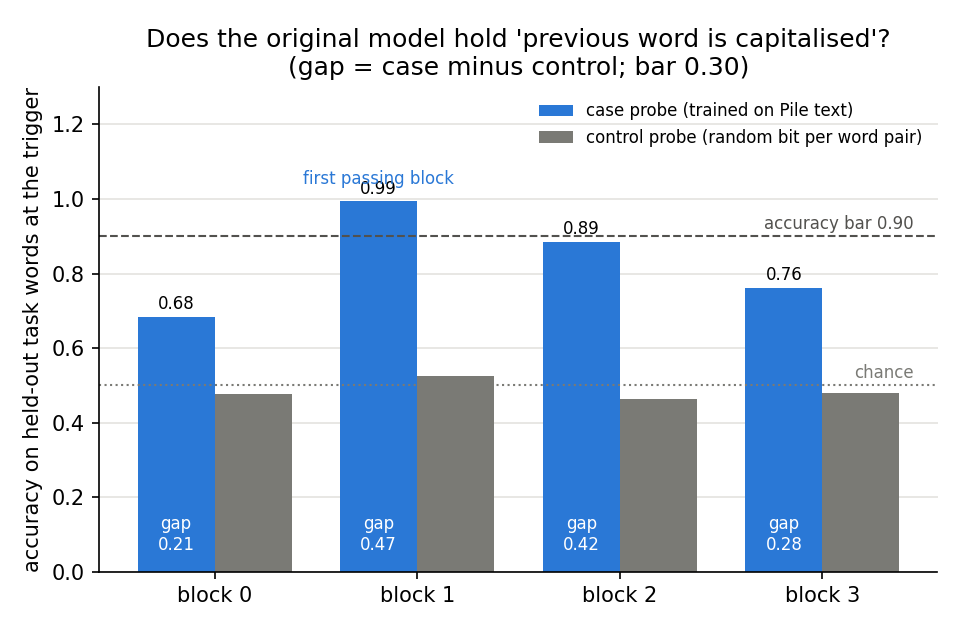

In [2]:
display(Image(FIG / "possession.png", width=750))


**Reading it.** Yes, after the second of the four blocks. There the case readout labels held-out words at the trigger right 99% of the time, while the random-label control sits near chance. The gap is 0.47 against a bar of 0.30. The first block and the third fall short of the 90% accuracy bar, and the last block does not count. Removing the case direction there barely disturbs the original model: its next-token loss rises by 0.003 nats.


## Does the fine-tune carry to unseen words, as a cut on the case readout?


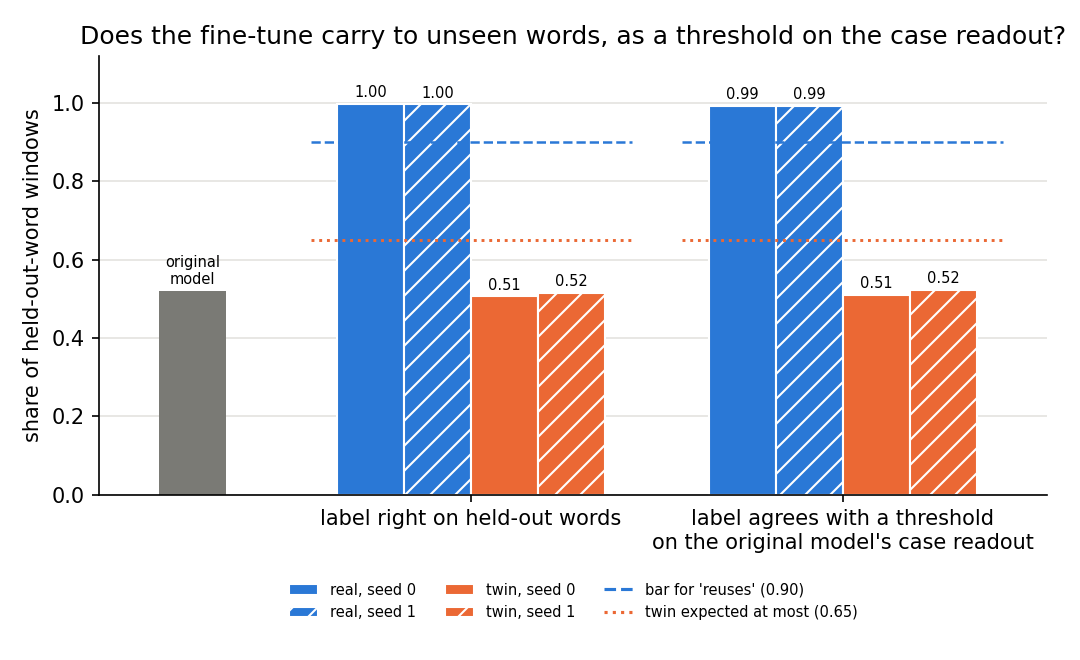

In [3]:
display(Image(FIG / "carrying.png", width=850))


**Reading it.** Yes for the real task on both seeds, and no for the twin, as predicted. The real fine-tunes label held-out words right almost every time, where the original model is at chance. A single cut on the original model's case readout, fitted on training words, matches their labels on 99% of held-out windows. The twins sit at chance on both measures, though they learned their training words. The caveat: when the readout reads case almost perfectly and the model labels by case almost perfectly, the two must agree. So this test separates real from twin, but not reading the feature from computing case some other way.


## Does removing the case direction take away the fine-tune's label gain?


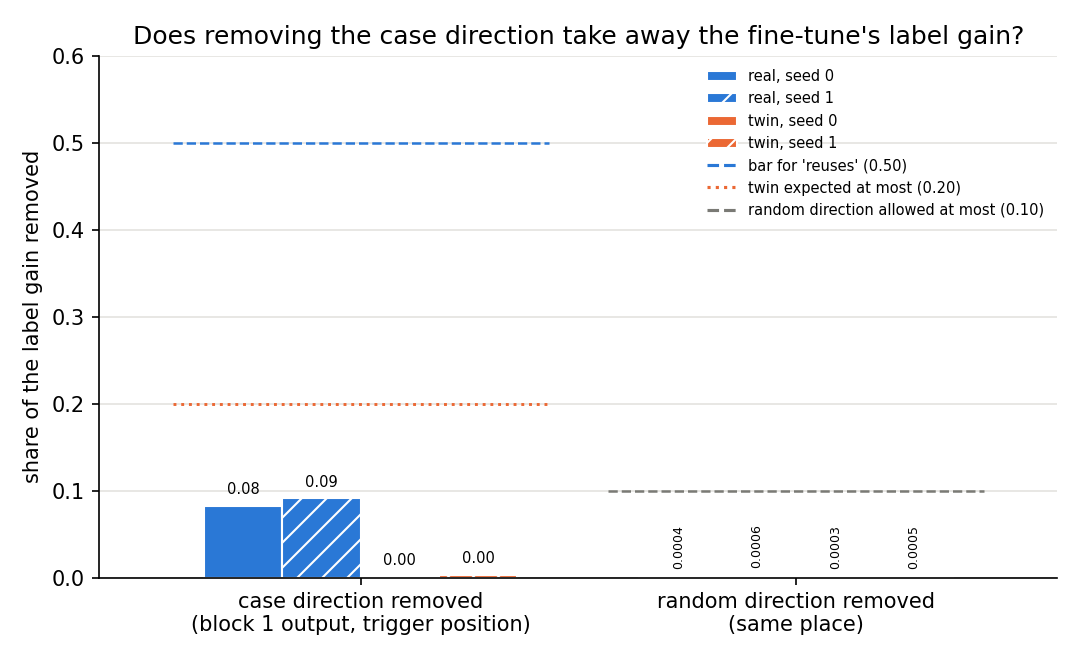

In [4]:
display(Image(FIG / "removal.png", width=850))


**Reading it.** No. Removing the case direction took 8% and 9% of the real fine-tunes' label gain, far under the bar of one half. A random direction in the same place took under a tenth of a percent on every state, and the twins lost almost nothing. So the direction matters to the real fine-tune, about thirty times more than a random one, but it carries only a small part of the behaviour. As filed, the real task reads "not through the capability".

Why the share is low is not known. Candidates, none tested:

- the case may still be present at the word's own position, where later heads can read it;
- case may sit in more than one direction at that block;
- the fine-tune may read it at a later block;
- one direction at one place may be too small a removal.


## Beside the verdict: pruning and reverse fine-tuning


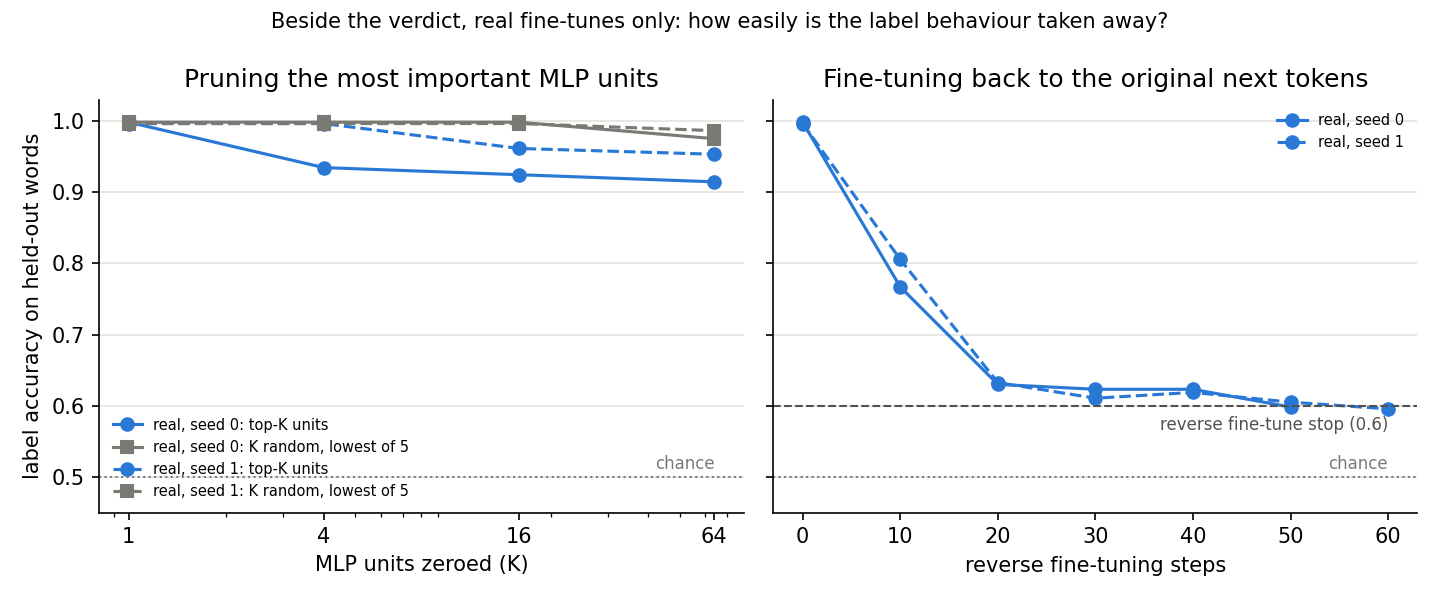

In [5]:
display(Image(FIG / "beside.png", width=950))


**Reading it.** No rule reads these. Zeroing the 64 most important MLP units of a real fine-tune left it labelling 91% and 95% of held-out words right, so no small set of units carries the behaviour. Fine-tuning back toward the original next tokens brought it to 60% within 50 to 60 steps. The twins start at chance on held-out words, so these say nothing about them.


## Amendment 1: does a stronger removal take the gain away?

The first removal took one direction out at one block and one position. The user approved one stronger try. It takes two directions out of the output of each of blocks 1, 2 and 3, at every position of the window, on the same four fine-tuned models.

- The first direction is the previous-word case readout from before, one per block.
- The second is a new own-word case readout: the same regression on the same Pile text, read at the word's own position, so it tracks whether the word itself is capitalised.

The two are made orthogonal at each block, so each block loses a two-dimensional subspace. The do-nothing reference takes two random directions out of the same places. The share removed and its bars are the same as before: one half for reuse, a fifth for the twin, a tenth for the random directions. The previous-word direction alone at the new places is shown beside it.


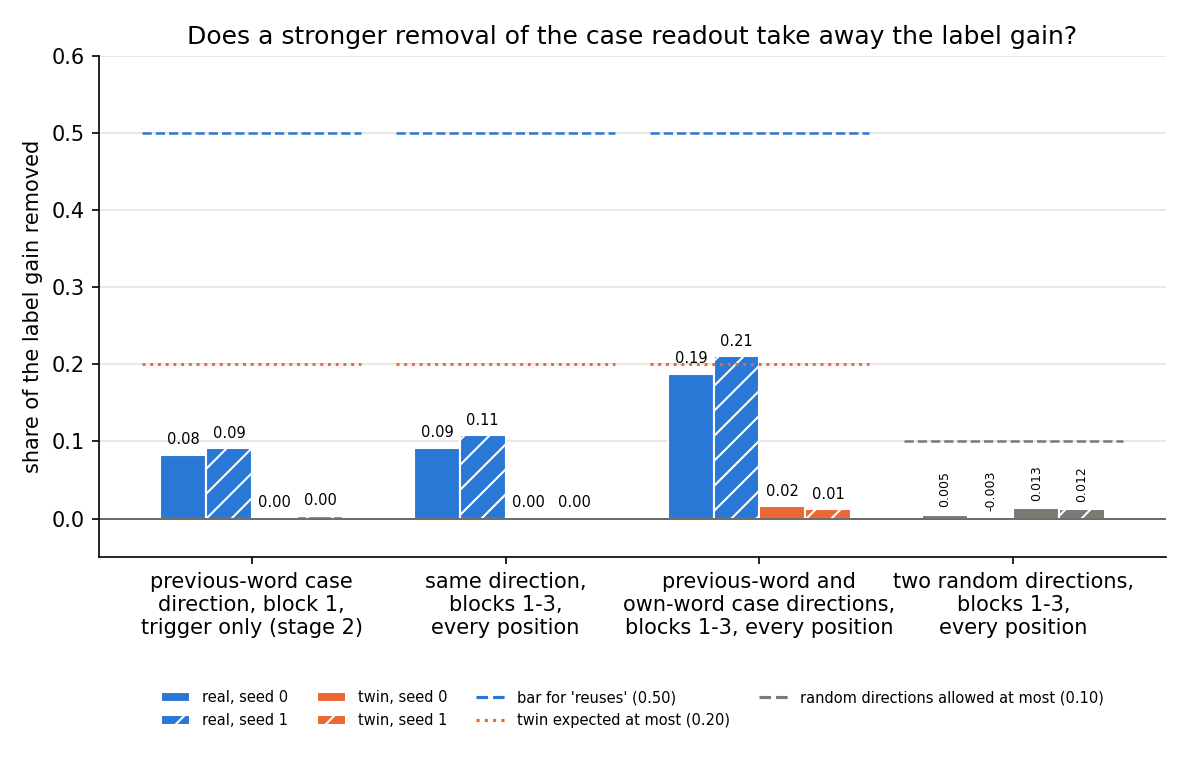

In [6]:
display(Image(FIG / "amend1_removal.png", width=900))


**Reading it.** No: the stronger removal took about a fifth of the real label gain, still far under one half. Removing both case directions took 0.19 and 0.21 of the real fine-tunes' gain. The previous-word direction alone at the same places took 0.09 and 0.11, barely more than at one place. So reaching every block and position added about a hundredth, and the own-word direction added about another tenth. The twins lost under 0.02, and two random directions took at most 0.013 on every state. As filed, the real task again reads "not through the capability", a second miss of our prediction.

The removal barely hurts the original model: its next-token loss rose by 0.045 nats from 3.43, about twice what two random directions cost. The own-word readout reads a held-out word's own case at 0.95 or better at every block.

Why the share stays low is not known. Candidates, none tested:

- case is part of each word's identity, so it may be spread over many directions, and a two-direction removal leaves it readable along others; no readout was refitted after the removal to check;
- the share is read on training words, whose labels the fine-tune could also have memorised;
- block 0 and the embeddings are untouched, and the fine-tune may read case nonlinearly.

No new rule is added. The user spent the last amendment on a removal that leaves no linear readout of case, next.


## Amendment 2: does erasing every linear trace of case take the gain away?

Amendment 1 removed two fixed directions per block. The last amendment removes as many as it takes to make case unreadable by a straight-line readout, after Ravfogel and colleagues' 2020 method. At each block, for each of the two case readouts, it fits the readout on Pile text, removes its direction, refits on what is left, and repeats. It stops once the readout is right at most 55% of the time on held-out words, or after 64 directions.

The removal is then applied at every position of blocks 1 to 3. The do-nothing reference removes the same number of random directions in the same places. It ran first and alone, and the job was filed to stop if that random removal took more than a tenth of any fine-tune's gain.


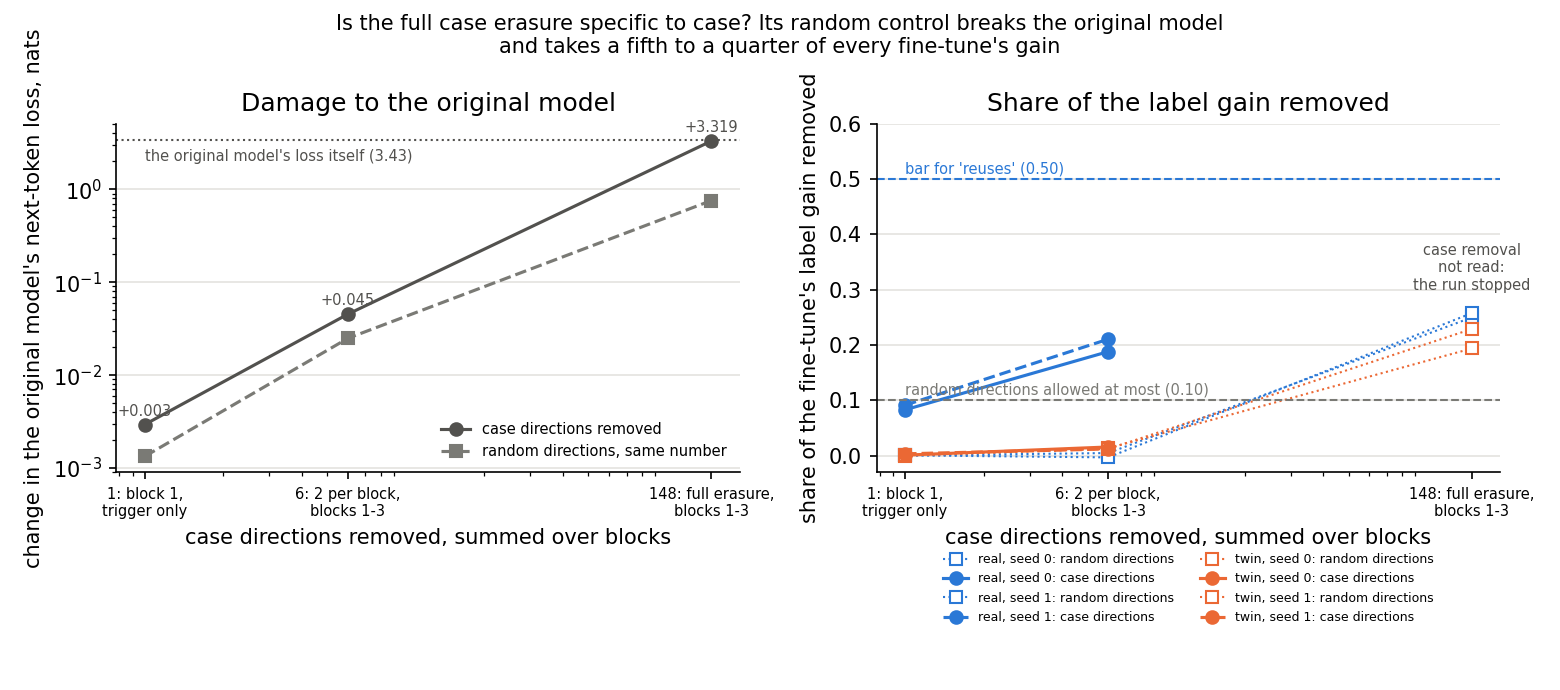

In [7]:
display(Image(FIG / "amend2_rank.png", width=950))


**Reading it.** The erasure is too large to be specific, so the run stopped as filed and gives no verdict. The erasure itself worked: both readouts fell to 55% or less at every block, using 148 directions over blocks 1 to 3, against six in Amendment 1. A fresh readout at the last block afterwards read the previous word's case at 49%, down from 79%.

The left panel shows the cost. The original model's next-token loss, 3.43 nats unedited, rose by 3.32 nats under the erasure, about doubling. The same number of random directions raised it by 0.76. The right panel shows the stop: those random directions alone took a fifth to a quarter of every fine-tune's label gain, over the allowed tenth, about as much as Amendment 1's case removal took. So removing case at this size also breaks the original model's next-token prediction, and the check cannot tell the fine-tune's reliance on case apart from general damage. No case share was read, and no cause for the earlier low shares is named.

**E112's final reading.** The real task reads "not through the capability" by the filed rule, from the first removal and Amendment 1, with possession, carrying and the small-function test passing. The twin reads "not through the capability", as filed. Both amendments are spent, so E112 is closed.


## What we learned

On the pair built to the definition's own shape, the definition does not read "reuses", though the real fine-tune looks like reuse on every test but the causal one. The twin separates from the real task on carrying and on the cut, so the apparatus tells a feature-reading fine-tune from a memorising one. The causal check decides. One direction at one place removed about a tenth of the gain, and two directions at every position of the last three blocks about a fifth. Erasing case completely took 148 directions, and at that size a random removal damages the original model as well, so this check could not be pushed further here. For the project's question of new capabilities against strengthened ones, this pair gives no outside reuse label.

## How compelling is the evidence

- Two seeds per arm, which agree within 0.03 on every scored number.
- One task pair, one model, one marker.
- The cut-on-the-readout test is blind once readout and labels are both near perfect.
- The first two removals are linear, one or two directions per block. They are blind to case carried in other directions, before block 1, or nonlinearly. Their random-direction floors are at most 0.013, so the real shares are well above noise and well below the bar.
- The full erasure's random floor is 0.19 to 0.26, over the allowed 0.10, so a case share at that size could not have been read apart from damage.
- The share is read on training words only.

## Surprises

The filed prediction that the real fine-tune reuses the case feature missed on both seeds, twice. We predicted removing the case direction would take at least half the label gain; it took under a tenth, and the stronger removal about a fifth. Every other number read as predicted. We cannot explain it.

The last amendment's stop was filed as possible, but its size was not expected: the erasure about doubled the original model's next-token loss.

## What next

- E112 is closed. Subject number, the second pair, does not run: the user's rule was that it runs only once case label reads cleanly, and it did not.
- The next step is the user's choice. On this pair the direction-removal check has reached its limit: the removal that erases case is as damaging as a random one of its size.


## Scorecard

| id | claim | rule | read | verdict |
|---|---|---|---|---|
| P0 | model holds case before the last block | accuracy ≥ 0.90, gap ≥ 0.30 | block 1: 0.994, gap 0.469 | pass, l* = 1 |
| do-nothing | random direction removes no gain | share ≤ 0.10, every state | ≤ 0.0006 | pass |
| P1 real | right on held-out words | ≥ 0.90 | 0.998, 0.996 | pass |
| P2 real | labels are a cut on the readout | ≥ 0.90 | 0.993, 0.992 | pass |
| P3 real | removal takes the gain | share ≥ 0.50 | 0.083, 0.091 | **miss** |
| real | "reuses C", both seeds | P1-P3 all | P3 misses | **"not through C"; filed outcome missed** |
| P1-P3 twin | at chance; removal spares it | ≤ 0.65, ≤ 0.65, ≤ 0.20 | 0.51-0.52, 0.51-0.52, ≤ 0.003 | **"not through C", as filed** |
| A1 do-nothing | two random directions remove no gain | share ≤ 0.10, every state | -0.003 to 0.013 | pass |
| A1 P3 real | two case directions, blocks 1-3, every position | share ≥ 0.50 | 0.188, 0.211 | **miss** |
| A1 real | "reuses C", both seeds | P1, P2, new P3 | P3 misses | **"not through C"; missed again** |
| A1 P3 twin | stronger removal spares the twin | ≤ 0.20 | 0.016, 0.012 | **"not through C", as filed** |
| A2 do-nothing | 148 random directions remove no gain | share ≤ 0.10, every state, else stop | 0.194 to 0.258 | **over: run stopped** |
| A2 P3 | full case erasure, blocks 1-3 | as A1 | not read | **no verdict** |
| E112 | final reading | stage 2 and A1 | | **real "not through C", missed; twin as filed; closed** |

## Departures from the literature

- The readout is a binary ridge regression at one block, not Jain et al.'s probe for their synthetic grammar, which our task lacks.
- Carrying to held-out words is the user's dated addition, `decisions.md` row 87.
- The direction removal is our addition, row 81; Jain et al.'s pruning and reverse fine-tuning run beside it without a rule.
- Amendment 1's own-word readout is a second readout used only inside the removal; Jain et al. have no such step.
- Amendment 2 follows Ravfogel et al.'s iterative erasure with our ridge readout in place of their linear classifier, so that it erases what the definition's readout reads.
- The fine-tune recipe is our earlier copy task's, not Jain et al.'s.

## Not run

- Amendment 2's case erasure on any fine-tune: the run stopped at its control.
- A third amendment: E112 has spent its two.
- Label accuracy on held-out words under any removal.
- A nonlinear removal.
- Subject number, the second pair: case label did not read cleanly.
- More seeds, markers or label words.
- Which subcomponents Γ switches on at this trigger.
- An independent check.

**Provenance.** Results `experiments/case_label/results/stage{0,1,2}.json`, `amend1.json` and `amend2.json`; report `reports/analyses/2026-11-06_analysis_e112-case-label.md`. Jobs 54048, 54052, 54054 on the cluster's debug queue, one L40, about ten minutes, no cost; Amendment 1 job 54094 and Amendment 2 job 54146, same queue, about a minute each, no cost.
